# Módulo 4: Compresión de la información de imagen

**Objetivo.** Evaluar algoritmos de compresión con y sin pérdida sobre el frame original y las ROIs segmentadas: Huffman, Run-Length Encoding (horizontal y vertical) y JPEG con factor de calidad Q = 90, 50, 10 y 5.

Toda la lógica está en `src/modulo4/compresion.py` y todos los parámetros en la sección `modulo4` de `config.yaml`; este notebook llama a las funciones, muestra los resultados y los discute. Las figuras y tablas se guardan en `results/modulo4/`.

## 0. Configuración del entorno e importaciones

In [1]:
# --- Imports de la librería estándar ---
import sys
from pathlib import Path

# --- Configurar la raíz del repositorio ---
# Se sube de carpeta hasta encontrar config.yaml: esa es la raíz.
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# --- Imports de terceros y propios ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from IPython.display import display

from src.config import cargar_config
from src.modulo1 import carga_muestreo as cm
from src.modulo2 import segmentacion as seg
from src.modulo2 import anotacion as an
from src.modulo4 import compresion as comp   # Para este notebook las funciones auxiliares están en compresion.py

# --- Estilo de las figuras ---
# Un color fijo por método (el mismo en todas las figuras).
COLOR = {"JPEG": "#2a78d6", "Huffman": "#eb6834", "RLE": "#1baf7a"}
COLOR_ZONA = {"borde_pupila": "#2a78d6", "iris": "#eb6834", "esclerotica": "#1baf7a"}
NOMBRE_ZONA = {"borde_pupila": "Borde pupilar", "iris": "Iris", "esclerotica": "Esclerótica"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "font.size": 10,
    "lines.linewidth": 2, "lines.markersize": 7,
})
pd.set_option("display.precision", 3)

## 1. Carga de datos e imágenes de trabajo

Se lee el frame definido en `config.yaml` (`entrada`) y se arman las imágenes a comprimir (lista `modulo4.imagenes`):

* **frame_original**: el frame original completo, en color (721×592 px, RGB).
* **2_1_6_watershed**, **2_1_4_otsu_mascara** y **2_1_5_Snake_mascara**: las máscaras binarias de la pupila (151×249 px, valores 0/255) obtenidas en el Módulo 2 con Watershed, Otsu y Snake, respectivamente.

Todas son `uint8`: sin comprimir ocupan **8 bits por muestra** (una "muestra" es un píxel en grises o un canal de un píxel a color). Ese es el tamaño de referencia para calcular el ratio de compresión. Las máscaras también se guardan en 8 bits aunque solo usen dos valores; esto es a propósito, para ver qué tanto aprovecha cada método esa redundancia.

In [2]:
cfg = cargar_config(raiz / "config.yaml")
c4 = cfg["modulo4"]

carpeta_res = raiz / "results" / "modulo4"
carpeta_res.mkdir(parents=True, exist_ok=True)

# Imágenes a comprimir: frame original + imágenes segmentadas del config
frame = cm.obtener_frame(cfg, raiz)
imagenes = comp.imagenes_de_trabajo(frame, cfg, raiz)

for nombre, im in imagenes.items():
    print(f"{nombre:18s} forma = {str(im.shape):15s} sin comprimir = {comp.bits_originales(im) / 8 / 1024:7.1f} KiB")

# ROI del ojo (para mirar los artefactos) y segmentación de referencia sobre
# el frame sin comprimir (para las zonas de la sección 5 y el diámetro)
def en_roi(img):
    return cm.recortar_roi(img, cfg["roi"])

x0, x1, y0, y1 = cm.roi_a_pixeles(frame.shape, cfg["roi"])
roi = en_roi(frame)                                # RGB, para mostrar
roi_orig = en_roi(imagenes["frame_original"])      # lo que efectivamente se comprimió
ref = comp.medir_pupila(roi, cfg)
if ref["mascara"] is None:
    raise RuntimeError("No se encontró la pupila en el frame de trabajo.")
print(f"\nPupila en el frame (cx, cy, r) = {ref['pupila']}  ->  diámetro equivalente = {ref['diametro_px']:.1f} px")

frame_original     forma = (850, 478, 3)   sin comprimir =  1190.3 KiB
2_1_6_watershed    forma = (111, 224)      sin comprimir =    24.3 KiB
2_1_4_otsu_mascara forma = (111, 224)      sin comprimir =    24.3 KiB
2_1_5_Snake_mascara forma = (111, 224)      sin comprimir =    24.3 KiB

Pupila en el frame (cx, cy, r) = (111.0, 48.0, 11.0)  ->  diámetro equivalente = 21.7 px


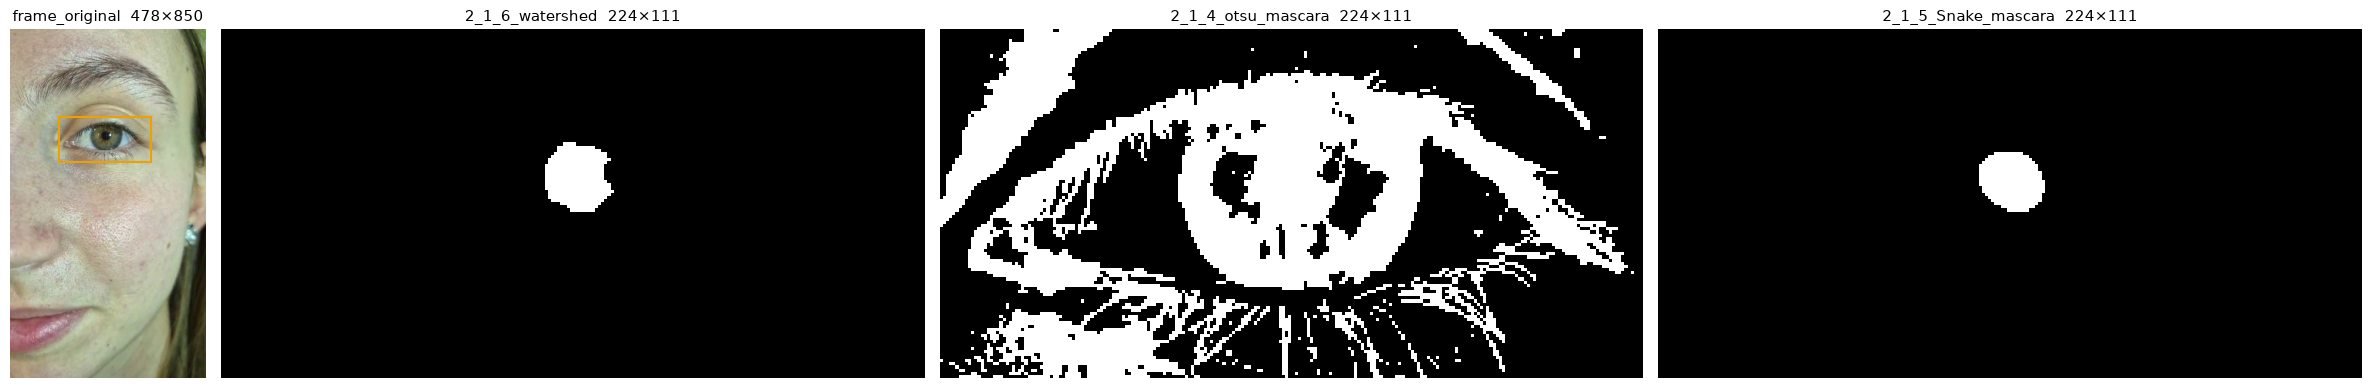

In [3]:
# Ancho de cada panel proporcional a la relación de aspecto de su imagen
proporciones = [im.shape[1] / im.shape[0] for im in imagenes.values()]
fig, ejes = plt.subplots(1, len(imagenes), figsize=(3.6 * sum(proporciones), 3.8),
                         gridspec_kw={"width_ratios": proporciones})
for ax, (nombre, im) in zip(np.atleast_1d(ejes), imagenes.items()):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{nombre}  {im.shape[1]}×{im.shape[0]}")
    ax.axis("off")
    if nombre == "frame_original":
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="#eda100", lw=1.5))
plt.tight_layout()
fig.savefig(carpeta_res / "4_0_imagenes_trabajo.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Aplicación de los esquemas de compresión

Se aplican los tres esquemas a cada imagen con `evaluar_compresion`. Para cada combinación se guarda el tamaño comprimido, el **ratio** (bits originales / bits comprimidos; mayor que 1 significa que ahorra espacio), los **bits por muestra** y la calidad de la reconstrucción (**PSNR** y **SSIM**, con las funciones del Módulo 1). En los métodos sin pérdida se verifica además que la imagen reconstruida sea idéntica bit a bit a la original (`sin_perdida`).

In [4]:
tabla, recs = comp.evaluar_compresion(
    imagenes,
    calidades=c4["calidades_jpeg"],
    bits_longitud_rle=c4["rle_bits_longitud"],
    verificar_huffman=c4["verificar_huffman"],
)
tabla.to_csv(carpeta_res / "4_tabla_compresion.csv", index=False)
print("¿Huffman y RLE reconstruyen exactamente la imagen?",
      tabla[tabla.metodo != "JPEG"].sin_perdida.all())

¿Huffman y RLE reconstruyen exactamente la imagen? True


### 2.1 Huffman

Huffman es un método de compresión sin pérdida que ataca la **redundancia de código**: en una imagen de 8 bits cada píxel ocupa 8 bits, aunque algunos niveles de gris aparezcan muchísimo más que otros. Para eliminarla, se asigna a cada nivel de gris un código binario de **longitud variable**: los niveles que más se repiten reciben códigos cortos y los poco frecuentes, códigos largos, sin perder la posición de cada píxel. El procedimiento es:

1. Se cuenta cuántas veces aparece cada nivel de gris (la tabla de frecuencias).
2. Se ordenan de menor a mayor frecuencia.
3. Se arma un árbol binario: cada nivel es una hoja con su frecuencia, y se unen de a dos las hojas de menor frecuencia en un nodo cuyo valor es la suma de ambas. Se repite con los nodos que van quedando hasta llegar a un único tronco, que suma la frecuencia total.
4. Por convención, a cada rama izquierda se le asigna "0" y a cada rama derecha "1"; el código de un nivel es la secuencia de ramas que hay que recorrer desde el tronco hasta su hoja.

Como los niveles frecuentes quedan cerca del tronco, tienen códigos cortos; los raros quedan lejos y tienen códigos largos. 

Se implementó la versión canónica: los códigos quedan determinados solo por sus longitudes, así que la cabecera guarda 256 longitudes (256 bytes) en lugar del árbol. El tamaño reportado incluye esa cabecera.

Para saber qué tan bien puede comprimir Huffman se usa la **entropía** H = −Σ pₖ·log₂(pₖ), donde pₖ es la frecuencia relativa de cada nivel de gris. Esta es  la cantidad mínima promedio de bits por muestra que hacen falta para representar esa distribución: cuanto más desparejas son las frecuencias, menor es H. La longitud media del código de Huffman (L̄) cumple H ≤ L̄ < H + 1, es decir, queda muy cerca de ese mínimo. Como Huffman asigna un código de al menos 1 bit a cada muestra, no puede bajar de 1 bit por muestra, aunque la entropía sea mucho menor.

In [5]:
cols = ["imagen", "entropia_bits", "long_media_codigo", "bits_por_muestra", "ratio", "sin_perdida"]
display(tabla[tabla.metodo == "Huffman"][cols].reset_index(drop=True))

,imagen,entropia_bits,long_media_codigo,bits_por_muestra,ratio,sin_perdida
0,frame_original,7.578,7.604,7.606,1.052,True
1,2_1_6_watershed,0.061,1.000,1.057,7.568,True
2,2_1_4_otsu_mascara,0.916,1.000,1.057,7.568,True
3,2_1_5_Snake_mascara,0.046,1.000,1.057,7.568,True


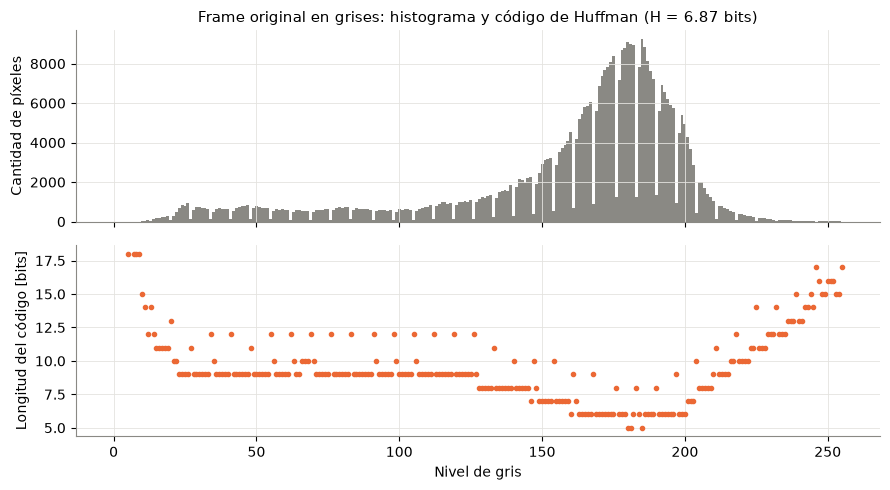

In [5]:
# Histograma del frame original (en grises) y longitud del código de cada nivel
frame_gris = comp.a_gris(imagenes["frame_original"])
frec = np.bincount(frame_gris.ravel(), minlength=256)
longitudes = comp.huffman_longitudes(frec)
niveles = np.arange(256)
usados = frec > 0

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
a1.bar(niveles, frec, width=1.0, color="#8a8984")
a1.set_ylabel("Cantidad de píxeles")
a1.set_title(f"Frame original en grises: histograma y código de Huffman (H = {comp.entropia(frame_gris):.2f} bits)")
a2.plot(niveles[usados], longitudes[usados], "o", ms=3, color=COLOR["Huffman"])
a2.set_ylabel("Longitud del código [bits]")
a2.set_xlabel("Nivel de gris")
plt.tight_layout()
fig.savefig(carpeta_res / "4_1_huffman_codigos.png", dpi=150, bbox_inches="tight")
plt.show()

Huffman actúa sobre la **redundancia de código**: sustituye los 8 bits fijos de cada nivel de gris por códigos de longitud variable, según cuánto se repite cada nivel. No actúa sobre la **redundancia de píxeles** (píxeles vecinos con el mismo valor), porque codifica cada muestra por separado y no mira a sus vecinas. Los resultados dependen de cuál de las dos redundancias predomine en la imagen.

En el frame hay poca redundancia de código: el histograma es ancho, se usan casi todos los 256 niveles y no hay unos pocos que dominen. La entropía es de ~7,6 bits por muestra (calculada sobre los tres canales de color; sobre la versión en grises del gráfico es de 6,87 bits), y la longitud media del código queda a menos de 0,03 bits de ese valor (7,604 contra 7,578): el código es prácticamente óptimo, pero no hay mucho que ahorrar y el ratio es de apenas ≈ 1,05. El gráfico muestra la regla del método: los niveles más frecuentes (≈165–200, el pico del histograma) reciben los códigos más cortos (5 a 7 bits), los intermedios, unos 9 bits, y los extremos, que casi no aparecen, de 15 a 18 bits. Con esos códigos se ahorra algo en el pico, pero se pierde en los extremos, y el resultado neto es casi nulo.

En las máscaras ocurre lo contrario: hay una redundancia de código enorme, porque cada píxel se guarda con 8 bits aunque solo tome dos valores (0 y 255). Huffman les asigna un código de 1 bit a cada uno, es decir, reduce la profundidad del píxel de 8 a 1 bit, y el ratio sube a ≈ 7,6 (8 bits sobre 1,057 bits por muestra). No puede pasar de ahí: la entropía de las máscaras es mucho menor (0,05 a 0,92 bits por muestra, según cuántos píxeles blancos tenga cada una), pero Huffman asigna como mínimo 1 bit a cada muestra, por eso las tres máscaras dan el mismo ratio. 

### 2.2 Run-Length Encoding (horizontal y vertical)

RLE reemplaza, para cada fila o columna, cada serie de valores iguales consecutivos (racha) por un par (longitud, valor), donde la longitud es el número de veces que se repite y el valor es el nivel de gris (en las máscaras binarias, 0 o 255). El valor ocupa 8 bits y la longitud `rle_bits_longitud` bits (8 por defecto, es decir, rachas de hasta 255; las más largas se parten). Cada par cuesta entonces 16 bits: RLE solo ahorra si las rachas miden aproximadamente más de 2 muestras.

El resultado depende del recorrido: horizontal (fila por fila) o vertical (columna por columna). En las imágenes a color se recorre cada canal por separado.

In [ ]:
cols = ["imagen", "metodo", "racha_media", "bits_por_muestra", "ratio", "sin_perdida"]
display(tabla[tabla.metodo.str.startswith("RLE")][cols].reset_index(drop=True))

,imagen,metodo,racha_media,bits_por_muestra,ratio,sin_perdida
0,frame_original,RLE horizontal,1.234,12.961,0.617,True
1,frame_original,RLE vertical,1.262,12.681,0.631,True
2,2_1_6_watershed,RLE horizontal,552.533,0.083,96.325,True
3,2_1_6_watershed,RLE vertical,507.429,0.092,86.899,True
4,2_1_4_otsu_mascara,RLE horizontal,11.155,1.438,5.562,True
5,2_1_4_otsu_mascara,RLE vertical,10.540,1.523,5.254,True
6,2_1_5_Snake_mascara,RLE horizontal,637.538,0.080,99.406,True
7,2_1_5_Snake_mascara,RLE vertical,578.233,0.088,90.703,True


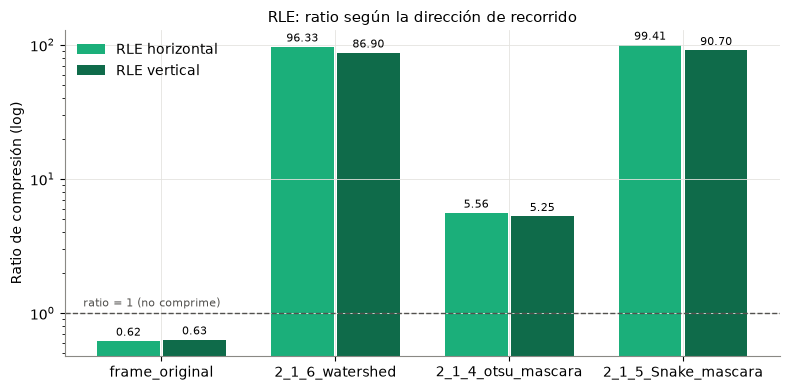

In [7]:
rle = tabla[tabla.metodo.str.startswith("RLE")].pivot(index="imagen", columns="metodo", values="ratio")
rle = rle.loc[list(imagenes)]
x = np.arange(len(rle))
fig, ax = plt.subplots(figsize=(8, 4))
for i, (direccion, tono) in enumerate([("RLE horizontal", COLOR["RLE"]), ("RLE vertical", "#0f6b4a")]):
    barras = ax.bar(x + (i - 0.5) * 0.38, rle[direccion], width=0.36, color=tono, label=direccion)
    ax.bar_label(barras, fmt="%.2f", fontsize=8, padding=2)
ax.axhline(1, color="#52514e", lw=1, ls="--")
ax.text(-0.45, 1.12, "ratio = 1 (no comprime)", ha="left", fontsize=8, color="#52514e")
ax.set_yscale("log")
ax.set_xticks(x, rle.index)
ax.set_ylabel("Ratio de compresión (log)")
ax.set_title("RLE: ratio según la dirección de recorrido")
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(carpeta_res / "4_2_rle_direcciones.png", dpi=150, bbox_inches="tight")
plt.show()

 RLE ataca la redundancia de píxeles, y solo funciona cuando hay muchos píxeles consecutivos con el mismo valor. En el frame (una imagen natural) casi no los hay: el ruido del sensor y la textura hacen que dos píxeles vecinos casi nunca sean exactamente iguales, y las rachas miden en promedio ≈1,2 muestras. Como cada par (valor, longitud) cuesta 16 bits y cada muestra original, 8, RLE expande la imagen: el ratio es de 0,617 en horizontal y 0,631 en vertical, es decir, el archivo queda ≈60 % más grande. Es el caso de la teoría: cuando los píxeles son muy aleatorios, RLE no conviene.

En las máscaras ocurre lo contrario: hay rachas de cientos de píxeles de fondo (la imagen se recorre como una única secuencia, así que una racha puede continuar de una fila a la siguiente) y RLE es el mejor método sin pérdida, con ratios de 96,3 (Watershed) en horizontal. La máscara de Otsu comprime mucho menos (5,6 en horizontal y 5,3 en vertical), porque su contorno tiene más transiciones y las rachas son más cortas.

El resultado depende del recorrido. En el frame la diferencia entre direcciones es de ≈2 %, dentro del redondeo de los ratios. En las máscaras, en cambio, el recorrido horizontal comprime más: un 11 % en Watershed (96,3 contra 86,9) y un 6 % en Otsu (5,56 contra 5,25). Una explicación posible es que en una región compacta, el número de rachas es proporcional a las veces que el recorrido cruza el objeto (dos transiciones por línea). Es decir, gana la dirección que cruza el objeto menos veces. Esto se puede comprobar midiendo el ancho y el alto de la máscara. Además, con 8 bits de longitud las rachas largas del fondo se parten cada 255 muestras, y esos cortes suman pares sin importar la dirección.

### 2.3 JPEG

JPEG es un método de compresión con pérdida: descarta la información a la que el ojo humano es menos sensible. Sigue los siguientes pasos:

1. **Cambio de espacio de color:** la imagen pasa de RGB a YUV: Y concentra la luminancia (el brillo) y U y V, la crominancia (los espacios cromáticos). Como el ojo es menos sensible a los detalles de color que a los de brillo, U y V se pueden submuestrear, es decir, se agranda el tamaño de su píxel y se guardan menos muestras de color. 
2. **División en bloques de 8×8** píxeles.
3. **Transformada discreta del coseno (DCT)** de cada bloque, después de centrar los valores entre −128 y 127. La DCT concentra las frecuencias bajas en la esquina superior izquierda del bloque y las altas en la esquina inferior derecha.
4. **Cuantización:** Cada coeficiente de la DCT se divide por el valor correspondiente de una matriz estándar (que se escala con el factor de calidad Q) y se redondea: a menor Q, mayor división y más coeficientes de alta frecuencia quedan en cero, que son los que el ojo detecta menos.
5. **Codificación sin pérdida:** los coeficientes se recorren en zig-zag, para que los ceros queden juntos al final, y se codifican con RLE y Huffman.
   
Para reconstruir la imagen se hace todo el camino inverso, bloque por bloque. Las dos etapas con pérdida (submuestreo y cuantización) no se pueden revertir, por lo que la imagen reconstruida no es idéntica a la original.

Se usa el códec de OpenCV (`cv2.imencode`), que submuestrea la crominancia por defecto. El tamaño es el del archivo `.jpg` completo, con sus cabeceras (tablas de cuantización y de Huffman: unos 330 bytes en grises y 630 a color).

In [8]:
cols = ["imagen", "parametro", "bytes_comprimido", "bits_por_muestra", "ratio", "psnr_db", "ssim"]
display(tabla[tabla.metodo == "JPEG"][cols].rename(columns={"parametro": "Q"}).reset_index(drop=True))

,imagen,Q,bytes_comprimido,bits_por_muestra,ratio,psnr_db,ssim
0,frame_original,90,86896.0,0.570,14.027,42.247,0.980
1,frame_original,50,34486.0,0.226,35.345,35.095,0.928
2,frame_original,10,11712.0,0.077,104.073,29.081,0.769
3,frame_original,5,8725.0,0.057,139.702,25.302,0.669
4,2_1_6_watershed,90,1148.0,0.369,21.659,54.962,0.998
5,2_1_6_watershed,50,875.0,0.282,28.416,41.126,0.989
6,2_1_6_watershed,10,707.0,0.227,35.168,33.746,0.983
7,2_1_6_watershed,5,676.0,0.218,36.781,28.155,0.110
8,2_1_4_otsu_mascara,90,13958.0,4.491,1.781,41.283,0.980
9,2_1_4_otsu_mascara,50,7544.0,2.427,3.296,27.216,0.875


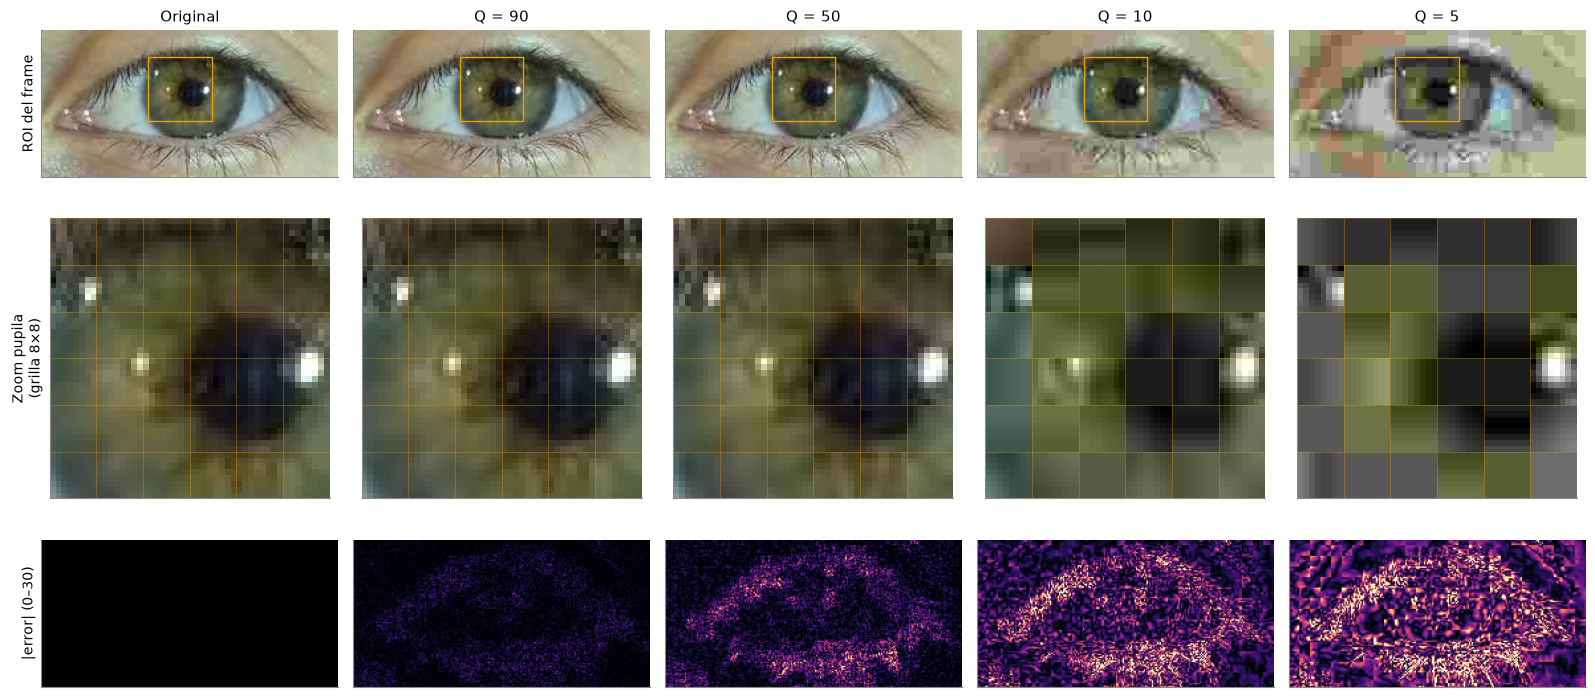

In [10]:
# Frame comprimido con cada Q, recortado a la ROI: zoom sobre la pupila con
# la grilla 8x8 de JPEG y mapa de error
calidades = c4["calidades_jpeg"]
versiones = [("Original", roi_orig)] + [
    (f"Q = {q}", en_roi(recs[("frame_original", f"JPEG Q={q}")])) for q in calidades]

cx, cy, r = ref["pupila"]
lado = 48                                   # zoom de 48x48 px (6x6 bloques)
# Esquina del zoom alineada a la grilla de 8 px DEL FRAME (que es lo que se comprimió)
zy0 = (y0 + int(cy) - lado // 2) // 8 * 8 - y0
zx0 = (x0 + int(cx) - lado // 2) // 8 * 8 - x0

fig, ejes = plt.subplots(3, len(versiones), figsize=(3.2 * len(versiones), 8.2))
for j, (titulo, im) in enumerate(versiones):
    ejes[0, j].imshow(im, cmap="gray")
    ejes[0, j].add_patch(plt.Rectangle((zx0, zy0), lado, lado, fill=False, ec="#eda100", lw=1))
    ejes[0, j].set_title(titulo)

    ejes[1, j].imshow(im[zy0:zy0 + lado, zx0:zx0 + lado], cmap="gray", interpolation="nearest")
    for k in range(0, lado + 1, 8):         # grilla de bloques de JPEG
        ejes[1, j].axhline(k - 0.5, color="#eda100", lw=0.4, alpha=0.6)
        ejes[1, j].axvline(k - 0.5, color="#eda100", lw=0.4, alpha=0.6)

    error = np.abs(comp.a_gris(im).astype(float) - comp.a_gris(roi_orig).astype(float))
    ejes[2, j].imshow(error, cmap="magma", vmin=0, vmax=30)
for ax in ejes.flat:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ejes[0, 0].set_ylabel("ROI del frame")
ejes[1, 0].set_ylabel("Zoom pupila\n(grilla 8×8)")
ejes[2, 0].set_ylabel("|error| (0–30)")
plt.tight_layout()
fig.savefig(carpeta_res / "4_3_jpeg_visual.png", dpi=150, bbox_inches="tight")
plt.show()

En el frame, el ratio crece al bajar Q mientras la calidad cae, pero no a un ritmo parejo. De Q = 90 a Q = 50 el ratio se multiplica por 2,5 (de 14 a 35) y el PSNR baja 7 dB (de 42 a 35 dB, con SSIM de 0,98 a 0,93). De Q = 50 a Q = 10 se multiplica por 3 (de 35 a 104) y el PSNR baja 6 dB más (a 29 dB), pero el SSIM cae mucho más (a 0,77). De Q = 10 a Q = 5, en cambio, el archivo solo se achica un 25 % (de 11 712 a 8725 bytes; ratio de 104 a 140) a costa de otros 4 dB de PSNR (a 25 dB) y 0,10 de SSIM: es el tramo con peor relación entre lo que se ahorra y lo que se pierde. Esto es consistente con el funcionamiento del método: al bajar Q, la tabla de cuantización divide cada coeficiente de la DCT por un número mayor, más coeficientes (primero los de alta frecuencia) se redondean a cero, y esos ceros quedan juntos al final del zig-zag, donde RLE y Huffman los comprimen muy bien. Pero pasado cierto punto ya se están descartando coeficientes de baja frecuencia, que sí aportan estructura visible, y el beneficio en tamaño se achica.

La figura muestra el mismo patrón en términos visuales. A Q = 90 el mapa de error es casi nulo y la imagen es indistinguible de la original; a Q = 50 aparece un error leve concentrado en los bordes de alto contraste (pestañas y párpado); a Q = 10 el error es intenso y la grilla de 8×8 es evidente en el zoom, con parches planos de color de mayor tamaño (consecuencia del submuestreo de la crominancia); y a Q = 5 la imagen queda dominada por bloques.

En las máscaras binarias, JPEG se comporta de otra manera. Como tienen solo dos valores y bordes abruptos, el ratio es mucho menor que en el frame para un mismo Q (a Q = 90, 22 en Watershed y solo 1,8 en Otsu, menos que Huffman con 7,6), porque un salto de 0 a 255 necesita muchos coeficientes de alta frecuencia para representarse. El ratio crece poco al bajar Q (de 22 a 37 en Watershed), porque el archivo ya es casi todo cabecera, y la calidad se resiente en el borde: en la máscara de Otsu el PSNR cae de 41 a 17 dB entre Q = 90 y Q = 5. Además, el SSIM de las máscaras de Watershed y Snake se desploma a Q = 5 (0,11) aunque el PSNR siga en 28 dB, por el desplazamiento del nivel del fondo que se explicó más arriba.

Luego, Q = 90 conserva la imagen prácticamente intacta con un ahorro de 14 veces; Q = 50 es un punto intermedio razonable (35 veces, PSNR de 35 dB); y por debajo de Q = 10 la ganancia ya no compensa la pérdida.

## 3. Evaluación comparativa: ratio y PSNR/SSIM vs ratio

Para trazar JPEG como una curva se repite la compresión con un barrido más fino de Q (`calidades_barrido`); los puntos marcan Q = 90, 50, 10 y 5 (de izquierda a derecha, en general). Huffman y RLE son sin pérdida: su PSNR es infinito (MSE = 0) y su SSIM es 1, por lo que se dibujan como puntos en el borde superior del gráfico, marcados "∞". RLE horizontal (círculo grande) y vertical (cuadrado chico) suelen quedar casi superpuestos.

In [11]:
barrido, recs_barrido = comp.barrido_jpeg(imagenes, c4["calidades_barrido"], c4["bloque_jpeg"])
barrido.to_csv(carpeta_res / "4_barrido_jpeg.csv", index=False)

# Resumen: ratio de cada método en cada imagen
resumen = tabla.assign(metodo=np.where(tabla.metodo == "JPEG", "JPEG Q=" + tabla.parametro.astype(str), tabla.metodo))
display(resumen.pivot(index="metodo", columns="imagen", values="ratio")[list(imagenes)]
        .loc[["Huffman", "RLE horizontal", "RLE vertical"] + [f"JPEG Q={q}" for q in c4["calidades_jpeg"]]])

imagen,frame_original,2_1_6_watershed,2_1_4_otsu_mascara,2_1_5_Snake_mascara
metodo,,,,
Huffman,1.112,7.365,7.365,7.365
RLE horizontal,0.617,96.325,5.562,99.406
RLE vertical,0.631,86.899,5.254,90.703
JPEG Q=90,14.027,21.659,1.781,21.926
JPEG Q=50,35.345,28.416,3.296,28.878
JPEG Q=10,104.073,35.168,7.376,35.318
JPEG Q=5,139.702,36.781,9.652,36.945


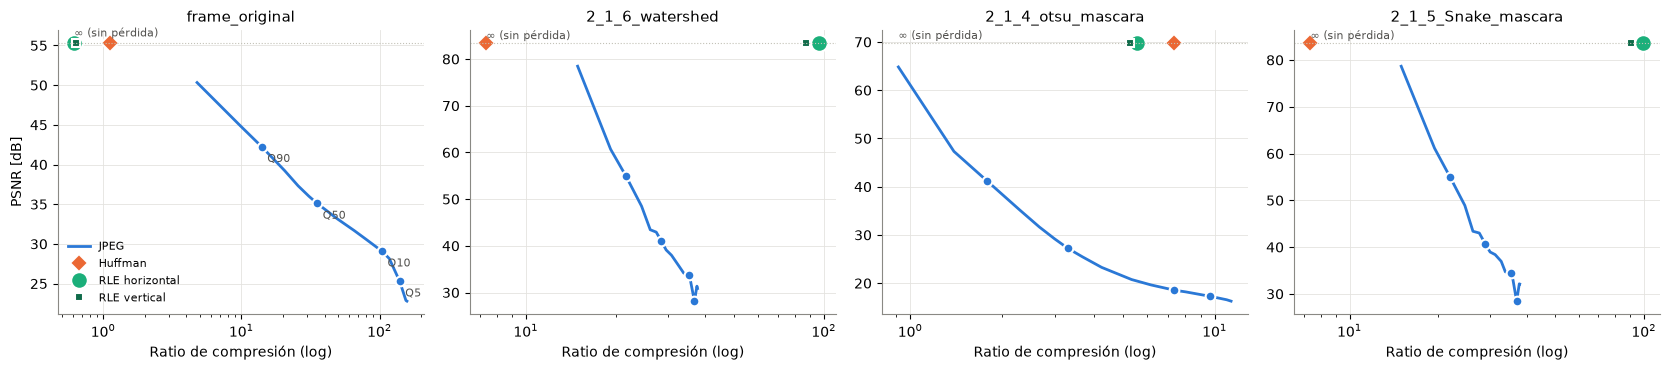

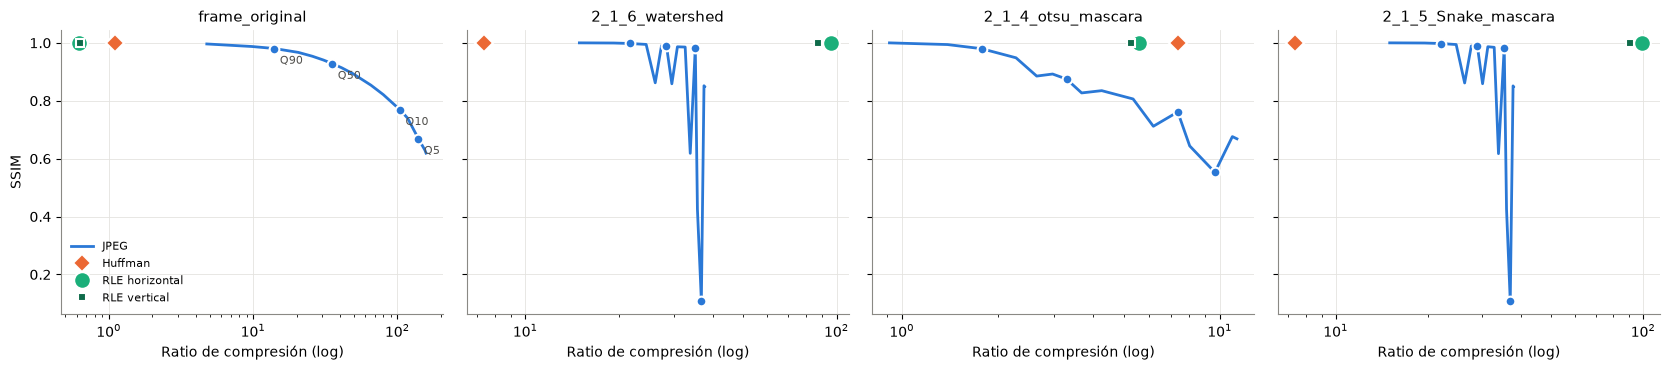

In [12]:
def graficar_vs_ratio(columna, etiqueta, archivo):
    n = len(imagenes)
    fig, ejes = plt.subplots(1, n, figsize=(4.2 * n, 3.8), sharey=(columna == "ssim"))
    for ax, nombre in zip(np.atleast_1d(ejes), imagenes):
        b = barrido[barrido.imagen == nombre]
        finitos = b[columna][np.isfinite(b[columna])]
        techo = (finitos.max() + 5) if columna == "psnr_db" else 1.0

        ax.plot(b.ratio, b[columna], "-", color=COLOR["JPEG"], label="JPEG")
        for q in c4["calidades_jpeg"]:      # se marcan los Q de la consigna
            f = b[b.parametro == q].iloc[0]
            ax.plot(f.ratio, f[columna], "o", color=COLOR["JPEG"], mec="white", mew=1.5)
            if nombre == "frame_original":  # en las segmentadas los puntos quedan muy juntos
                ax.annotate(f"Q{q}", (f.ratio, f[columna]), textcoords="offset points",
                            xytext=(4, -11), fontsize=8, color="#52514e")

        t = tabla[tabla.imagen == nombre]
        for metodo, marca, color, tam in [("Huffman", "D", COLOR["Huffman"], 9),
                                          ("RLE horizontal", "o", COLOR["RLE"], 12),
                                          ("RLE vertical", "s", "#0f6b4a", 6)]:
            f = t[t.metodo == metodo].iloc[0]
            ax.plot(f.ratio, techo, marca, color=color, mec="white", mew=1.5, ms=tam, label=metodo)
        if columna == "psnr_db":
            ax.axhline(techo, color="#c3c2b7", lw=0.8, ls=":")
            ax.text(min(b.ratio.min(), t.ratio.min()), techo + 0.8, "∞ (sin pérdida)", fontsize=8, color="#52514e")
        ax.set_xscale("log")
        ax.set_title(nombre)
        ax.set_xlabel("Ratio de compresión (log)")
    np.atleast_1d(ejes)[0].set_ylabel(etiqueta)
    np.atleast_1d(ejes)[0].legend(frameon=False, fontsize=8, loc="lower left")
    plt.tight_layout()
    fig.savefig(carpeta_res / archivo, dpi=150, bbox_inches="tight")
    plt.show()

graficar_vs_ratio("psnr_db", "PSNR [dB]", "4_4_psnr_vs_ratio.png")
graficar_vs_ratio("ssim", "SSIM", "4_4_ssim_vs_ratio.png")

**Discusión (comparativa).** En las imágenes naturales **JPEG domina con amplitud**: con Q = 90 el frame se reduce 18 veces manteniendo PSNR = 44 dB y SSIM = 0,985 (diferencias imperceptibles), y con Q = 50 se reduce 44 veces con PSNR = 38 dB. Los métodos sin pérdida, en cambio, no pasan de un ratio de 1,05. La ROI comprime menos que el frame a igual Q (26 vs 44 a Q = 50) por dos motivos: tiene proporcionalmente más detalle (pestañas, iris) y las cabeceras fijas del archivo JPEG (~630 bytes a color) pesan mucho en una imagen chica: a Q = 5 son ~40 % de los 1527 bytes.

En las imágenes binarias o casi vacías se invierte el orden: **RLE logra más compresión que JPEG y sin perder nada** (104 vs 31–45 en la máscara). JPEG no está pensado para bordes abruptos blanco/negro: los "salpica" con oscilaciones (efecto Gibbs) y a Q bajo desplaza el nivel del fondo. Ese desplazamiento explica la caída abrupta del SSIM a Q = 5 (0,10) con un PSNR todavía razonable (29 dB): el fondo pasa de 0 a ~8 niveles de gris y el término de luminancia del SSIM, (2μₓμᵧ + C₁)/(μₓ² + μᵧ² + C₁), se desploma cuando una de las medias es ≈ 0. Por eso, en imágenes casi negras el SSIM hay que leerlo con cuidado. En estas imágenes el ratio de JPEG además deja de crecer al bajar Q, porque el archivo ya es casi todo cabecera.

En resumen: para guardar el video o los frames conviene JPEG (Q ≥ 50 si después se va a medir), y para guardar máscaras de segmentación conviene un método sin pérdida basado en rachas (RLE o PNG).

## 4. Artefactos de bloque: ¿a partir de qué Q aparecen?

Como JPEG cuantiza cada bloque de 8×8 por separado, a Q bajo los bloques vecinos dejan de "empalmar" y aparece un escalón de intensidad justo sobre la grilla. Además de mirarlo, se mide con un **índice de bloques**:

B = (diferencia media entre píxeles vecinos que **cruzan** un borde de bloque) / (diferencia media entre vecinos **dentro** de un bloque)

Sin artefactos B ≈ 1 (los bordes de la grilla no tienen nada especial); con blocking B > 1. Se calcula sobre la luminancia, con `indice_bloques`.

Hay que tener en cuenta que el frame "original" ya viene comprimido: es una captura de un video de celular (H.264, que también trabaja por bloques), así que puede traer artefactos propios. Por eso se compara contra el índice de la imagen original.

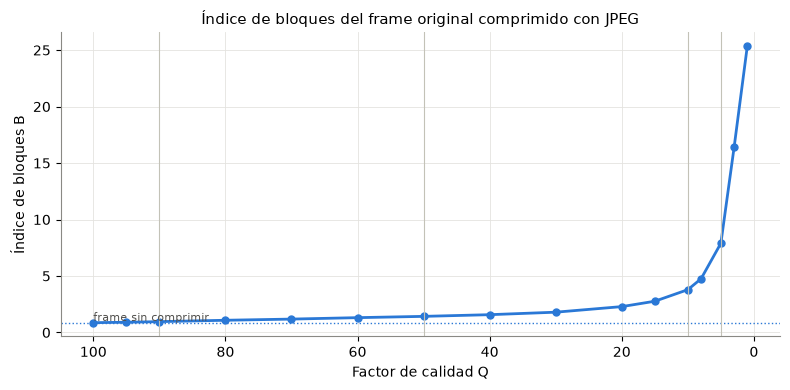

Frame sin comprimir: B = 0.87


parametro,100,95,90,80,70,60,50,40,30,20,15,10,8,5,3,1
indice_bloques,0.867,0.904,0.958,1.080,1.184,1.311,1.425,1.574,1.795,2.289,2.765,3.789,4.753,7.899,16.381,25.350
psnr_db,50.330,44.895,42.247,39.224,37.318,36.010,35.095,34.224,33.164,31.679,30.582,29.081,28.156,25.302,22.873,22.790
ssim,0.996,0.987,0.980,0.967,0.954,0.940,0.928,0.914,0.893,0.854,0.821,0.769,0.740,0.669,0.629,0.619


In [13]:
b = barrido[barrido.imagen == "frame_original"]
b_original = comp.indice_bloques(imagenes["frame_original"], c4["bloque_jpeg"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(b.parametro, b.indice_bloques, "o-", color=COLOR["JPEG"], ms=5)
ax.axhline(b_original, color=COLOR["JPEG"], lw=1, ls=":")
ax.text(100, b_original + 0.15, "frame sin comprimir", fontsize=8, color="#52514e", ha="left")
for q in c4["calidades_jpeg"]:
    ax.axvline(q, color="#c3c2b7", lw=0.8)
ax.invert_xaxis()                          # Q decreciente = más compresión hacia la derecha
ax.set_xlabel("Factor de calidad Q")
ax.set_ylabel("Índice de bloques B")
ax.set_title("Índice de bloques del frame original comprimido con JPEG")
plt.tight_layout()
fig.savefig(carpeta_res / "4_5_indice_bloques.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Frame sin comprimir: B = {b_original:.2f}")
display(b.set_index("parametro")[["indice_bloques", "psnr_db", "ssim"]].T)

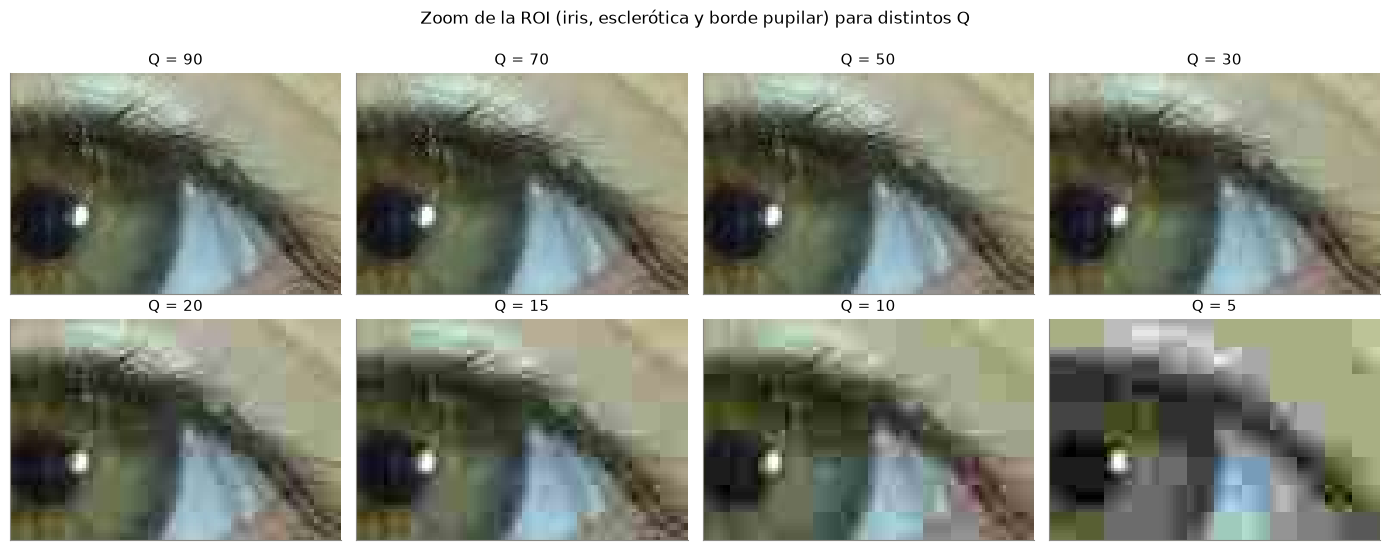

In [14]:
# Barrido visual fino sobre una zona con esclerótica, borde del iris y pupila
_, iris = seg.estimar_pupila(seg.segmentar_pupila(roi, cfg)["gris"], devolver_iris=True)
icx, icy, ir = iris
# Esquina del zoom (coordenadas de la ROI) alineada a la grilla 8x8 del frame
zy = (y0 + int(max(icy - 1.1 * ir, 0))) // 8 * 8 - y0
zx = (x0 + int(max(icx - 0.2 * ir, 0))) // 8 * 8 - x0
alto_z, ancho_z = 64, 96

qs_vista = [90, 70, 50, 30, 20, 15, 10, 5]
fig, ejes = plt.subplots(2, 4, figsize=(14, 5.6))
for ax, q in zip(ejes.flat, qs_vista):
    im = en_roi(recs_barrido[("frame_original", q)])
    ax.imshow(im[zy:zy + alto_z, zx:zx + ancho_z], interpolation="nearest")
    ax.set_title(f"Q = {q}")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.suptitle("Zoom de la ROI (iris, esclerótica y borde pupilar) para distintos Q", y=1.0)
plt.tight_layout()
fig.savefig(carpeta_res / "4_5_blocking_visual.png", dpi=150, bbox_inches="tight")
plt.show()

**Discusión (artefactos de bloque).** El índice B crece de forma continua al bajar Q: vale 1,00 sin comprimir, 1,14 a Q = 90, 1,62 a Q = 50, 2,36 a Q = 20 y 3,49 a Q = 10 (frame), y se dispara por debajo de Q = 10 (5,9 a Q = 5). A la vista, a escala normal no se distinguen bloques hasta Q ≈ 50; en el zoom empiezan a insinuarse en la piel y la esclerótica alrededor de **Q = 30**, son **claramente visibles a Q = 20** y a Q = 10 dominan la imagen. A Q = 10 y 5 aparecen además manchas de color de 16×16 px: JPEG submuestrea la crominancia (4:2:0), así que cada bloque de color cubre 16×16 píxeles y, al cuantizarlo fuerte, queda un color plano por bloque (el iris se vuelve verde o gris por parches).

Se puede ubicar entonces el umbral de aparición de los blocking artifacts **entre Q = 30 y Q = 20**, y a Q = 10 ya son evidentes. Hay que tener en cuenta que el frame de trabajo es una captura de un video de celular (H.264), que ya pasó por una compresión por bloques; no se detectó un blocking previo (B ≈ 1 en el original), pero sí puede haber perdido detalle fino.

## 5. ¿Los artefactos se notan más en el borde pupilar o en las regiones uniformes?

Se definen tres zonas de la ROI a partir de la segmentación (`zonas_ojo`, parámetros en `modulo4.zonas`):

* **Borde pupilar**: franja de ±2 px alrededor del contorno de la máscara de la pupila (el borde nítido oscuro/claro).
* **Iris**: disco del iris (hasta 0,85·r_iris) sin la pupila ni su borde.
* **Esclerótica**: corona entre 1,3 y 1,8·r_iris, solo a los costados del iris (filas entre cy − 0,3·r_iris y cy + 0,6·r_iris) para no tomar párpados ni pestañas.

En cada zona se mide el **RMSE** (error medio en niveles de gris), el **SSIM** promedio del mapa SSIM, y la **textura local** del original (desvío estándar en ventanas de 7×7 px, promediado en la zona). El cociente RMSE/textura indica qué tan grande es el error comparado con la variación propia de la zona: un mismo error se ve mucho más sobre una zona lisa que sobre una con textura o con un borde (efecto de enmascaramiento).

In [15]:
z = c4["zonas"]
zonas = comp.zonas_ojo(ref["mascara"], iris, z["ancho_borde_px"], z["factor_iris"],
                       z["esclerotica_rango"], z["esclerotica_filas"])
print({NOMBRE_ZONA[k]: int(v.sum()) for k, v in zonas.items()}, "píxeles por zona")

filas = []
for q in c4["calidades_barrido"]:
    fila = {"Q": q}
    fila.update(comp.error_por_zona(roi_orig, en_roi(recs_barrido[("frame_original", q)]), zonas,
                                z["ventana_textura"]))
    filas.append(fila)
por_zona = pd.DataFrame(filas)
for k in zonas:
    por_zona[f"rmse/textura_{k}"] = por_zona[f"rmse_{k}"] / por_zona[f"textura_{k}"]
por_zona.to_csv(carpeta_res / "4_error_por_zona.csv", index=False)

display(por_zona[por_zona.Q.isin(c4["calidades_jpeg"])].set_index("Q").T)

{'Borde pupilar': 385, 'Iris': 2367, 'Esclerótica': 1180} píxeles por zona


Q,90,50,10,5
rmse_borde_pupila,2.470,5.392,11.335,15.093
ssim_borde_pupila,0.991,0.963,0.856,0.808
textura_borde_pupila,25.026,25.026,25.026,25.026
rmse_iris,1.719,4.156,8.517,11.841
ssim_iris,0.987,0.940,0.766,0.637
textura_iris,11.405,11.405,11.405,11.405
rmse_esclerotica,2.081,5.055,11.312,14.627
ssim_esclerotica,0.989,0.944,0.773,0.686
textura_esclerotica,15.579,15.579,15.579,15.579
rmse/textura_borde_pupila,0.099,0.215,0.453,0.603


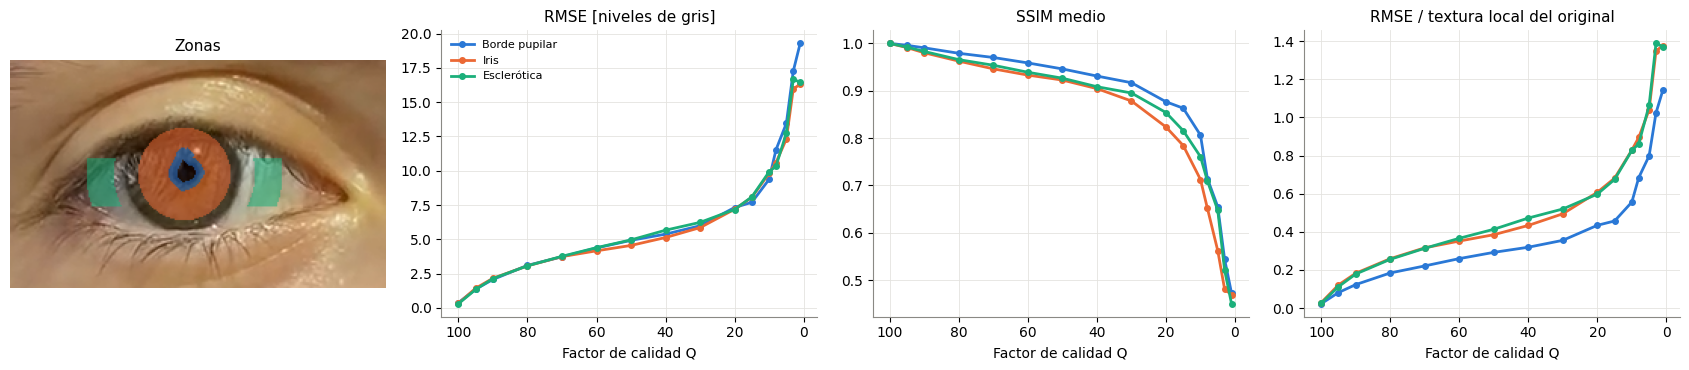

In [16]:
fig, ejes = plt.subplots(1, 4, figsize=(17, 3.8))

vista = roi.copy()
for k, col in COLOR_ZONA.items():
    rgb = np.array([int(col[i:i + 2], 16) for i in (1, 3, 5)])
    vista[zonas[k]] = (0.45 * vista[zonas[k]] + 0.55 * rgb).astype(np.uint8)
ejes[0].imshow(vista)
ejes[0].set_title("Zonas")
ejes[0].axis("off")

for ax, (pref, etiqueta) in zip(ejes[1:], [("rmse_", "RMSE [niveles de gris]"),
                                           ("ssim_", "SSIM medio"),
                                           ("rmse/textura_", "RMSE / textura local del original")]):
    for k in zonas:
        ax.plot(por_zona.Q, por_zona[pref + k], "o-", ms=4, color=COLOR_ZONA[k], label=NOMBRE_ZONA[k])
    ax.invert_xaxis()
    ax.set_xlabel("Factor de calidad Q")
    ax.set_title(etiqueta)
ejes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(carpeta_res / "4_6_error_por_zona.png", dpi=150, bbox_inches="tight")
plt.show()

**Discusión (bordes vs regiones uniformes).** En valor absoluto el error es parecido en las tres zonas (RMSE ≈ 4,4–4,9 a Q = 50 y ≈ 9,2–10,0 a Q = 10): JPEG reparte el error en todo el bloque. Lo que cambia es **cuánto se nota**:

* El **SSIM es más alto en el borde pupilar** que en el iris y la esclerótica entre Q = 95 y Q = 5 (0,95 vs 0,92 a Q = 50; 0,80 vs 0,73–0,74 a Q = 10): la estructura del borde (un salto fuerte oscuro/claro) sobrevive, mientras que la de las zonas lisas se pierde.
* **Relativo a la textura propia de cada zona**, el error es un 30–50 % mayor en el iris y la esclerótica que en el borde (0,41 y 0,37 contra 0,27 a Q = 50; 0,83 y 0,77 contra 0,58 a Q = 10). En una zona lisa cualquier escalón entre bloques es la única "estructura" que hay, y se ve; en el borde, el contraste alto lo enmascara.

Por eso **los artefactos de bloque son más notorios en las regiones uniformes** (esclerótica, piel, iris), como se ve en el barrido visual. En los bordes nítidos de la pupila el artefacto típico es otro: suavizado y oscilaciones (*ringing*), porque se descartan las frecuencias altas que forman el borde. Ese efecto es menos visible, pero es justamente el que puede mover el contorno que usa la segmentación (sección 6).

Una salvedad: en este frame el "iris" no es una región tan lisa (el estroma tiene textura) y su textura local resultó similar a la de la esclerótica, que tiene sombras y vasos. Con un video de mayor resolución la diferencia entre zonas probablemente sería más marcada.

## 6. ¿La compresión a Q = 50/10 cambia el diámetro pupilar?

Se comprime el **frame completo** con JPEG (como lo haría la cámara o el códec de video), se recorta la ROI y se segmenta con el mismo pipeline elegido en el Módulo 2 (`segmentar_pupila`: CLAHE + Watershed; si `modulo2.morfologia.operacion_final` tiene un valor, se aplica también esa operación). El diámetro se toma como el **diámetro equivalente** (el del círculo de igual área): D = 2·√(A/π).

> El Módulo 3 todavía no está en el repositorio; cuando esté, conviene reemplazar `comp.medir_pupila` por su función de área/diámetro para que la comparación use exactamente la misma medida.

In [16]:
tabla_d, medidas = comp.diametro_vs_calidad(frame, cfg, c4["diametro"]["calidades"])
tabla_d.to_csv(carpeta_res / "4_diametro_vs_calidad.csv", index=False)
display(tabla_d)

,version,calidad,area_px,diametro_px,radio_estimado_px,delta_diametro_px,delta_diametro_pct,dice_vs_original
0,original,NaN,369,21.675,11.0,0.000,0.000,1.000
1,Q=90,90.0,371,21.734,11.0,0.059,0.271,0.984
2,Q=50,50.0,426,23.289,11.0,1.614,7.446,0.913
3,Q=10,10.0,439,23.642,11.0,1.967,9.073,0.894
4,Q=5,5.0,402,22.624,11.0,0.948,4.376,0.911


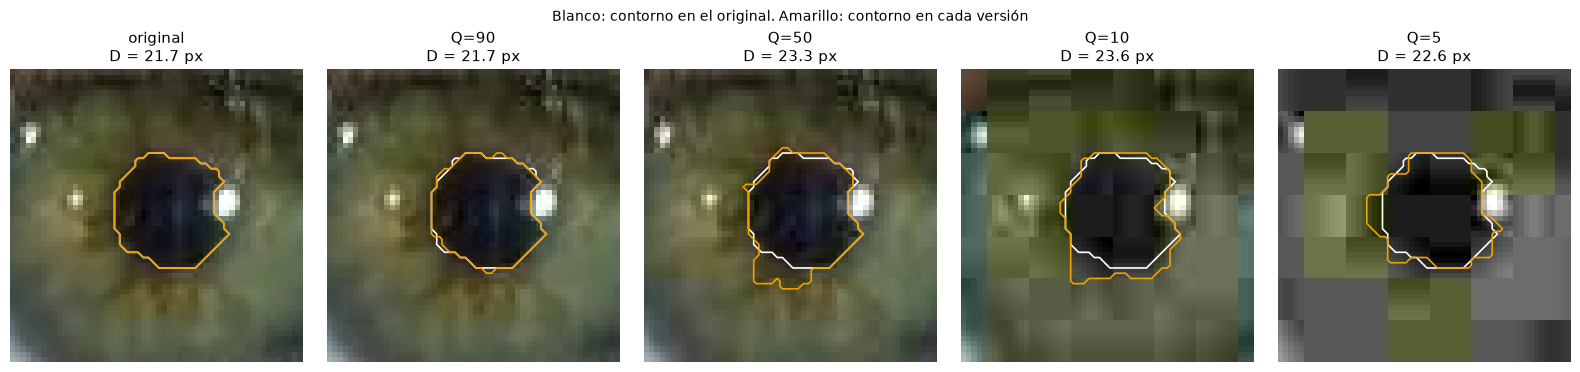

In [17]:
# Contorno segmentado en cada versión (zoom alrededor de la pupila)
lado = 56
zy0, zx0 = max(int(cy) - lado // 2, 0), max(int(cx) - lado // 2, 0)
fig, ejes = plt.subplots(1, len(medidas), figsize=(3.2 * len(medidas), 3.6))
for ax, (etiqueta, med) in zip(ejes, medidas.items()):
    img_v = frame if etiqueta == "original" else comp.jpeg_ida_y_vuelta(frame, int(etiqueta[2:]))[0]
    roi_v = cm.recortar_roi(img_v, cfg["roi"])
    ax.imshow(roi_v[zy0:zy0 + lado, zx0:zx0 + lado], interpolation="nearest")
    for m, col in [(medidas["original"]["mascara"], "white"), (med["mascara"], "#eda100")]:
        if m is not None:
            ax.contour(m[zy0:zy0 + lado, zx0:zx0 + lado] > 0, levels=[0.5], colors=col, linewidths=1.2)
    ax.set_title(f"{etiqueta}\nD = {med['diametro_px']:.1f} px")
    ax.axis("off")
plt.suptitle("Blanco: contorno en el original. Amarillo: contorno en cada versión", y=1.02, fontsize=10)
plt.tight_layout()
fig.savefig(carpeta_res / "4_7_diametro_contornos.png", dpi=150, bbox_inches="tight")
plt.show()

**Discusión (diámetro en el frame de trabajo).** **Sí, la compresión cambia el diámetro estimado**, y más de lo que haría pensar el PSNR. Respecto del original (18,5 px):

* Q = 90: +0,6 px (+3,5 %), Dice entre máscaras 0,96.
* **Q = 50: +2,6 px (+14 %)**, Dice 0,85.
* **Q = 10: +3,5 px (+19 %)**, Dice 0,76.
* Q = 5: +1,3 px (+7 %), pero con Dice 0,79: el diámetro "parecido" es casualidad, la forma de la máscara es otra.

El motivo se ve en los contornos: Watershed inunda sobre el gradiente de Sobel, y JPEG suaviza el borde de la pupila y lo mezcla con el reflejo corneal que está pegado arriba a la derecha. Con un borde menos nítido, la línea divisoria se corre hacia afuera y la máscara "se escapa" hacia el reflejo. Como la pupila es chica (~20 px de diámetro, unos 2–3 bloques de 8×8), un corrimiento de 1–2 px en el borde ya es un 10–20 % del diámetro.

Para dimensionarlo: en el Módulo 2 la máscara de Watershed ya salía 1,4–1,8 veces más grande que la manual en área, así que a Q = 50 el error por compresión es comparable al error propio del método. Esto es importante para el Módulo 3: si el video o los frames se guardan con JPEG a Q ≤ 50, el cambio de diámetro por compresión puede confundirse con parte de la respuesta fotomotora. **Conviene medir siempre sobre el video original (o con Q ≥ 90)**. Este resultado es de un solo frame; la sección siguiente lo extiende a todo el video.

### 6.1 A lo largo del video

Un solo frame puede engañar: el cambio de diámetro podría deberse a ese frame en particular. Si el video de `entrada.video_path` está disponible (y `modulo4.diametro.usar_video` es `true`), se mide D(t) en el original y en cada Q, tomando 1 de cada `paso_frames` frames, y se resume la diferencia |ΔD| respecto del original. Si además están las anotaciones manuales del Módulo 2 y coinciden con la ROI del video, se compara cada versión contra la medición manual: así se ve si el cambio por compresión es chico o grande frente al error propio de la segmentación.

334 frames analizados; diámetro medio en el original = 27.0 px


,|ΔD| medio [px],|ΔD| medio [%],|ΔD| máx [px],frames sin pupila
version,,,,
Q=90,1.110,3.695,18.464,0
Q=50,1.424,4.894,19.703,0
Q=10,2.437,8.384,19.777,1
Q=5,6.370,22.881,23.660,2


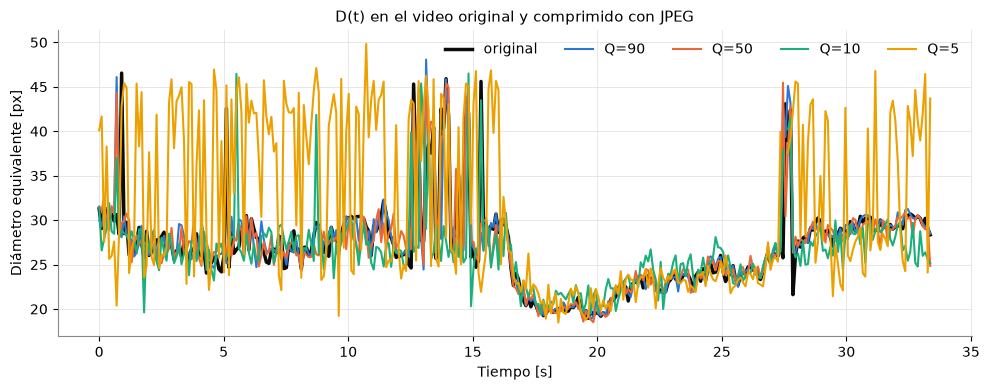

In [18]:
ruta_video = raiz / cfg["entrada"]["video_path"]
hay_video = c4["diametro"]["usar_video"] and ruta_video.exists()
if not hay_video:
    print(f"Se saltea el análisis en video: no se encontró {ruta_video} (o usar_video = false).")
else:
    curva = comp.diametro_en_video(ruta_video, cfg, c4["diametro"]["calidades"],
                                   paso_frames=c4["diametro"]["paso_frames"])
    curva.to_csv(carpeta_res / "4_diametro_video.csv", index=False)

    orden = ["original"] + [f"Q={q}" for q in c4["diametro"]["calidades"]]
    ancha = curva.pivot(index="t_s", columns="version", values="diametro_px")[orden]
    dif = ancha.drop(columns="original").sub(ancha["original"], axis=0)
    resumen_video = pd.DataFrame({
        "|ΔD| medio [px]": dif.abs().mean(),
        "|ΔD| medio [%]": (100 * dif.abs().div(ancha["original"], axis=0)).mean(),
        "|ΔD| máx [px]": dif.abs().max(),
        "frames sin pupila": ancha.drop(columns="original").isna().sum(),
    })
    print(f"{len(ancha)} frames analizados; diámetro medio en el original = {ancha['original'].mean():.1f} px")
    display(resumen_video)

    tonos = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(ancha.index, ancha["original"], color="#0b0b0b", lw=2.5, label="original")
    for col, tono in zip([c for c in ancha.columns if c != "original"], tonos):
        ax.plot(ancha.index, ancha[col], color=tono, lw=1.5, label=col)
    ax.set_xlabel("Tiempo [s]")
    ax.set_ylabel("Diámetro equivalente [px]")
    ax.set_title("D(t) en el video original y comprimido con JPEG")
    ax.legend(frameon=False, ncol=len(ancha.columns))
    plt.tight_layout()
    fig.savefig(carpeta_res / "4_8_diametro_video.png", dpi=150, bbox_inches="tight")
    plt.show()

In [19]:
# Comparación contra la anotación manual del Módulo 2 (si corresponde a este video)
carpeta_anot = raiz / "results" / "modulo2" / "anotaciones_manuales"
anotaciones = dict(sorted(an.cargar_anotaciones(carpeta_anot).items())) if carpeta_anot.exists() else {}

if not (hay_video and anotaciones):
    print("Se saltea la comparación con la anotación manual (falta el video o las anotaciones).")
else:
    forma_roi = cm.recortar_roi(cm.extraer_frame(ruta_video, 0), cfg["roi"]).shape[:2]
    forma_anot = next(iter(anotaciones.values())).shape
    if forma_roi != forma_anot:
        print(f"Las anotaciones ({forma_anot}) no coinciden con la ROI del video ({forma_roi}); "
              "probablemente son de otro video. Se saltea.")
    else:
        d_auto = comp.diametro_en_video(ruta_video, cfg, c4["diametro"]["calidades"],
                                        tiempos=list(anotaciones))
        orden = ["original"] + [f"Q={q}" for q in c4["diametro"]["calidades"]]
        d_auto = d_auto.pivot(index="t_s", columns="version", values="diametro_px")[orden]
        d_manual = pd.Series({t: comp.diametro_equivalente(m)[0] for t, m in anotaciones.items()})
        err = d_auto.sub(d_manual, axis=0)
        display(pd.DataFrame({"MAE vs manual [px]": err.abs().mean(),
                              "RMSE vs manual [px]": np.sqrt((err ** 2).mean()),
                              "sesgo medio [px]": err.mean()}))

,MAE vs manual [px],RMSE vs manual [px],sesgo medio [px]
version,,,
original,1.152,1.821,-0.509
Q=90,1.032,1.472,-0.402
Q=50,1.506,1.717,-0.032
Q=10,3.039,3.531,-0.240
Q=5,4.245,7.030,2.042


**Cómo leer esta sección.** Si D(t) con Q = 50 o Q = 10 sigue de cerca la curva original, la compresión no afecta la medición; si aparecen picos o un corrimiento sistemático, sí. El |ΔD| medio en px y en % resume cuánto se separa cada versión del original, y la cantidad de frames sin pupila indica si a algún Q la segmentación directamente falla. Si la comparación con la anotación manual está disponible, el cambio por compresión debe compararse con el MAE de la versión original: si es mucho menor, la compresión no es la fuente de error dominante.

> En esta ejecución el video de `entrada.video_path` no estaba en `data/videos/` (los videos no se suben al repositorio), así que estas celdas se saltearon. Para completarlas hay que copiar el video a esa ruta y volver a correr el notebook.

## 7. Conclusiones

1. **Sin pérdida, en imágenes naturales casi no se gana nada**: Huffman queda en un ratio de 1,05 (la entropía es ~7,5 bits) y RLE incluso agranda la imagen (0,6–0,7), porque las rachas miden en promedio menos de 2 píxeles. La dirección de recorrido de RLE cambia el ratio menos de un 4 %.
2. **En máscaras binarias el panorama se invierte**: RLE comprime ~104 veces sin perder nada y supera a JPEG, que además distorsiona los bordes y el nivel del fondo. Huffman queda limitado a 1 bit por píxel (ratio ≈ 7,6).
3. **JPEG ofrece la mejor relación ratio/calidad en imágenes naturales**: Q = 90 da un ratio de 18 con PSNR = 44 dB y SSIM = 0,985 en el frame; Q = 50, un ratio de 44 con PSNR = 38 dB.
4. **Los artefactos de bloque empiezan a verse entre Q = 30 y Q = 20** y son evidentes a Q = 10 (índice de bloques 3,5 contra 1,0 del original). Por debajo aparecen además parches de color de 16×16 por el submuestreo de crominancia.
5. **Los artefactos se notan más en las regiones uniformes** (esclerótica, piel, iris): allí el SSIM es menor y el error relativo a la textura es 30–50 % mayor que en el borde pupilar, donde el contraste alto los enmascara.
6. **La compresión sí cambia el diámetro pupilar**: +14 % a Q = 50 y +19 % a Q = 10 en el frame de trabajo, porque el borde suavizado hace que Watershed se extienda hacia el reflejo corneal. Para el análisis del reflejo fotomotor conviene segmentar sobre el video original o con Q ≥ 90.

Limitaciones: la evaluación de calidad y del diámetro se hizo sobre un frame que ya viene comprimido por el códec del celular; la pupila mide ~20 px, por lo que cualquier corrimiento de 1–2 px es un cambio relativo grande; y el diámetro se calculó como diámetro equivalente sobre la máscara de Watershed, que debería reemplazarse por la medida definitiva del Módulo 3 cuando esté.